# Used car prices: should the dealer buy this car?

Predict a car's sale price with linear regression, compare it with just guessing the average price, then use both to decide which auction cars to buy.

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, root_mean_squared_error

PREP_COST = 1500
sales = pd.read_csv("used_car_sales.csv")
lots = pd.read_csv("auction_lots.csv")

sales["Accident"] = sales["Accident"].map({"yes": 1, "no": 0})
lots["Accident"] = lots["Accident"].map({"yes": 1, "no": 0})

print(len(sales), "cars sold")
print(len(lots), "auction lots")
sales.head()

240 cars sold
40 auction lots


,Sale_Price,Mileage_K,Age_Years,Horsepower,Accident,Num_Owners
0,35300,7,2,240,0,2
1,12800,125,8,190,1,3
2,30200,40,3,170,0,1
3,33300,56,3,285,1,3
4,21700,63,8,225,0,2


In [42]:
sales.describe()

,Sale_Price,Mileage_K,Age_Years,Horsepower,Accident,Num_Owners
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,26077.500000,53.650000,4.741667,202.333333,0.233333,2.058333
std,7078.442285,33.147105,2.563000,43.667790,0.423836,0.810969
min,5300.000000,3.000000,1.000000,120.000000,0.000000,1.000000
25%,22150.000000,28.500000,3.000000,170.000000,0.000000,1.000000
50%,26550.000000,52.000000,4.000000,200.000000,0.000000,2.000000
75%,30600.000000,71.000000,6.000000,230.000000,0.000000,3.000000
max,45200.000000,157.000000,12.000000,350.000000,1.000000,4.000000


## 1. Split the data

70% of the cars to fit the model, 30% kept aside to test it. `random_state=42` gives the same split every time.

In [43]:
train, test = train_test_split(sales, test_size=0.3, random_state=42)

print("Training cars:", len(train))
print("Test cars:", len(test))

Training cars: 168
Test cars: 72


## 2. Fit the model

First with all five features.

In [44]:
full = smf.ols("Sale_Price ~ Mileage_K + Age_Years + Horsepower + Accident + Num_Owners", data=train).fit()
print(full.summary())

                            OLS Regression Results                            
Dep. Variable:             Sale_Price   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.869
Method:                 Least Squares   F-statistic:                     222.7
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.19e-70
Time:                        04:03:31   Log-Likelihood:                -1559.5
No. Observations:                 168   AIC:                             3131.
Df Residuals:                     162   BIC:                             3150.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    2.17e+04   1093.279     19.847      0.0

Then without `Num_Owners`.

In [45]:
reduced = smf.ols("Sale_Price ~ Mileage_K + Age_Years + Horsepower + Accident", data=train).fit()
print(reduced.summary())

                            OLS Regression Results                            
Dep. Variable:             Sale_Price   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     280.0
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           6.78e-72
Time:                        04:03:31   Log-Likelihood:                -1559.5
No. Observations:                 168   AIC:                             3129.
Df Residuals:                     163   BIC:                             3145.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2.176e+04   1023.723     21.258      0.0

In [46]:
print("Adjusted R² with all 5 features:", round(full.rsquared_adj, 4))
print("Adjusted R² without Num_Owners: ", round(reduced.rsquared_adj, 4))

Adjusted R² with all 5 features: 0.8691
Adjusted R² without Num_Owners:  0.8698


In [47]:
v1 = reduced

## 3. Baseline vs v1 on the test cars

The baseline guesses the average price of the training cars for every car.

In [48]:
baseline_price = train["Sale_Price"].mean()
print("Baseline guess for every car:", round(baseline_price))

actual = test["Sale_Price"]
baseline_pred = [baseline_price] * len(test)
v1_pred = v1.predict(test)

baseline_r2 = r2_score(actual, baseline_pred)
baseline_rmse = root_mean_squared_error(actual, baseline_pred)
v1_r2 = r2_score(actual, v1_pred)
v1_rmse = root_mean_squared_error(actual, v1_pred)

print(f"Baseline: R² = {baseline_r2:.3f}, RMSE = ${baseline_rmse:,.0f}")
print(f"v1:       R² = {v1_r2:.3f}, RMSE = ${v1_rmse:,.0f}")

Baseline guess for every car: 25851
Baseline: R² = -0.014, RMSE = $6,494
v1:       R² = 0.823, RMSE = $2,716


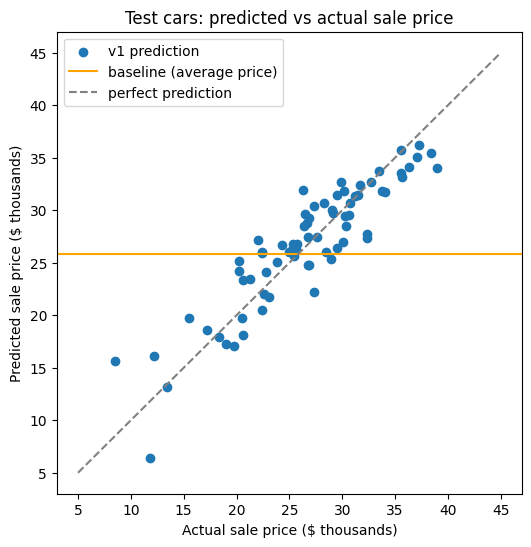

In [49]:
plt.figure(figsize=(6, 6))
plt.scatter(actual / 1000, v1_pred / 1000, label="v1 prediction")
plt.axhline(baseline_price / 1000, color="orange", label="baseline (average price)")
plt.plot([5, 45], [5, 45], color="gray", linestyle="--", label="perfect prediction")
plt.xlabel("Actual sale price ($ thousands)")
plt.ylabel("Predicted sale price ($ thousands)")
plt.title("Test cars: predicted vs actual sale price")
plt.legend()
plt.savefig("predicted_vs_actual.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Buy or pass at the auction

Rule: buy the car if auction price + $1,500 is less than the price we expect it to sell for. The baseline rule uses the average price as the expected price for every car.

Profit on a car we buy = later sale price - auction price - $1,500.

In [50]:
def v1_rule(car, auction_price):
    predicted_price = v1.predict(car).iloc[0]
    if auction_price + PREP_COST < predicted_price:
        return "buy"
    else:
        return "pass"


def baseline_rule(car, auction_price):
    if auction_price + PREP_COST < baseline_price:
        return "buy"
    else:
        return "pass"

In [51]:
features = ["Mileage_K", "Age_Years", "Horsepower", "Accident", "Num_Owners"]

baseline_choices = []
v1_choices = []
for i in range(len(lots)):
    car = lots.loc[[i], features]
    auction_price = lots.loc[i, "Auction_Price"]
    baseline_choices.append(baseline_rule(car, auction_price))
    v1_choices.append(v1_rule(car, auction_price))

lots["baseline"] = baseline_choices
lots["v1"] = v1_choices
lots["predicted_price"] = v1.predict(lots).round()
lots["profit_if_bought"] = lots["Later_Sale_Price"] - lots["Auction_Price"] - PREP_COST

lots[["Lot", "Auction_Price", "predicted_price", "Later_Sale_Price", "profit_if_bought", "baseline", "v1"]]

,Lot,Auction_Price,predicted_price,Later_Sale_Price,profit_if_bought,baseline,v1
0,1,21500,17466.0,19000,-4000,buy,pass
1,2,36100,31162.0,35600,-2000,pass,pass
2,3,26600,25703.0,28100,0,pass,pass
3,4,37800,34324.0,36700,-2600,pass,pass
4,5,23300,25416.0,24500,-300,buy,buy
5,6,28000,24155.0,28900,-600,pass,pass
6,7,24600,21864.0,22600,-3500,pass,pass
7,8,18300,20332.0,18600,-1200,buy,buy
8,9,29600,29609.0,28600,-2500,pass,pass
9,10,22400,22061.0,20500,-3400,buy,pass


In [52]:
for rule in ["baseline", "v1"]:
    bought = lots[lots[rule] == "buy"]
    losing = bought[bought["profit_if_bought"] < 0]
    total_profit = bought["profit_if_bought"].sum()

    print(rule)
    print("  cars bought:", len(bought))
    print("  money-losing cars:", len(losing))
    print(f"  total profit: ${total_profit:,}")

baseline
  cars bought: 14
  money-losing cars: 10
  total profit: $-6,000
v1
  cars bought: 17
  money-losing cars: 6
  total profit: $15,800


## 5. Which cars the baseline buys

In [53]:
cols = ["Mileage_K", "Age_Years", "Horsepower", "Accident"]
print(lots[lots["baseline"] == "buy"][cols].mean())
print(sales[cols].mean())

Mileage_K      80.857143
Age_Years       6.928571
Horsepower    173.571429
Accident        0.357143
dtype: float64
Mileage_K      53.650000
Age_Years       4.741667
Horsepower    202.333333
Accident        0.233333
dtype: float64


In [54]:
print(lots[lots["baseline"] == "buy"]["Later_Sale_Price"].mean())

17771.428571428572
